In [3]:
import itertools
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from gan_data import get_dataloaders, unpaired, denorm

device = 'cuda' if torch.cuda.is_available() else 'cpu'
dl = get_dataloaders(size=256, batch_size=1, num_workers=0)

# from torch.utils.data import DataLoader, Subset
# dl.train_Black = DataLoader(Subset(dl.train_Black.dataset, range(2000)),
#                            batch_size=1, shuffle=True, drop_last=True)
# dl.train_Blond = DataLoader(Subset(dl.train_Blond.dataset, range(2000)),
#                            batch_size=1, shuffle=True, drop_last=True)

# A 域 = 黑发 -> train_Black ；B 域 = 金发 -> train_Blond
print('train_Black', len(dl.train_Black.dataset), '张')
print('train_Blond', len(dl.train_Blond.dataset), '张')
print('test_Black ', len(dl.test_Black.dataset), '张')
print('test_Blond ', len(dl.test_Blond.dataset), '张')


train_Black 38775 张
train_Blond 23984 张
test_Black  9694 张
test_Blond  5996 张


In [4]:
def DiscriminatorBLOND():
    return nn.Sequential(nn.Conv2d(3, 64, 4, 2, 1),    #(n, 64, 128, 128)
                         nn.LeakyReLU(0.2, inplace = True),

                         nn.Conv2d(64, 128, 4, 2, 1),    #(n, 128, 64, 64)
                         nn.InstanceNorm2d(128),
                         nn.LeakyReLU(0.2, inplace = True),

                         nn.Conv2d(128, 256, 4, 2, 1),
                         nn.InstanceNorm2d(256),
                         nn.LeakyReLU(0.2, inplace = True),

                         nn.Conv2d(256, 512, 4, 1, 1),
                         nn.InstanceNorm2d(512),
                         nn.LeakyReLU(0.2, inplace = True),

                         nn.Conv2d(512, 1, 4, 1, 1)).to(device)

def DiscriminatorBLACK():
    return nn.Sequential(nn.Conv2d(3, 64, 4, 2, 1),    #(n, 64, 128, 128)
                         nn.LeakyReLU(0.2, inplace = True),

                         nn.Conv2d(64, 128, 4, 2, 1),    #(n, 128, 64, 64)
                         nn.InstanceNorm2d(128),
                         nn.LeakyReLU(0.2, inplace = True),

                         nn.Conv2d(128, 256, 4, 2, 1),
                         nn.InstanceNorm2d(256),
                         nn.LeakyReLU(0.2, inplace = True),

                         nn.Conv2d(256, 512, 4, 1, 1),
                         nn.InstanceNorm2d(512),
                         nn.LeakyReLU(0.2, inplace = True),

                         nn.Conv2d(512, 1, 4, 1, 1)).to(device)

In [5]:
class ResnetBlock(nn.Module):
    """CycleGAN 残差块。out = x + conv_block(x)"""

    def __init__(self, dim, use_bias=True):
        super().__init__()
        self.conv_block = nn.Sequential(
            nn.ReflectionPad2d(1),
            nn.Conv2d(dim, dim, kernel_size=3, padding=0, bias=use_bias),
            nn.InstanceNorm2d(dim, affine=False, track_running_stats=False),
            nn.ReLU(inplace=True),

            nn.ReflectionPad2d(1),
            nn.Conv2d(dim, dim, kernel_size=3, padding=0, bias=use_bias),
            nn.InstanceNorm2d(dim, affine=False, track_running_stats=False),
        )

    def forward(self, x):
        return x + self.conv_block(x)          # 加法后直接返回，没有激活

In [6]:
def GeneratorBLOND():
    return nn.Sequential(nn.ReflectionPad2d(3),    #镜面padding，图像生成常用
                         nn.Conv2d(3, 64, 7, 1, 0),    #(n, 64, 256, 256)
                         nn.InstanceNorm2d(64),
                         nn.ReLU(inplace = True),

                         nn.Conv2d(64, 128, 3, 2, 1),    #(n, 128, 128, 128)
                         nn.InstanceNorm2d(128),
                         nn.ReLU(inplace = True),

                         nn.Conv2d(128, 256, 3, 2, 1),    #(n, 256, 64, 64)
                         nn.InstanceNorm2d(256),
                         nn.ReLU(inplace = True),

                         # ---------- 9 个残差块：尺寸和通道都不变 ----------
                         ResnetBlock(256),    #(n, 256, 64, 64)
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),

                         # ---------- 上采样 x2 ----------
                         # output_padding=1 不能省，否则尺寸会变成 63 / 255
                         nn.ConvTranspose2d(256, 128, 3, 2, 1, 1),    #(n, 128, 128, 128)
                         nn.InstanceNorm2d(128),
                         nn.ReLU(inplace = True),

                         nn.ConvTranspose2d(128, 64, 3, 2, 1, 1),    #(n, 64, 256, 256)
                         nn.InstanceNorm2d(64),
                         nn.ReLU(inplace = True),

                         nn.ReflectionPad2d(3),
                         nn.Conv2d(64, 3, 7, 1, 0),    #(n, 3, 256, 256)
                         nn.Tanh()).to(device)


def GeneratorBLACK():
    return nn.Sequential(nn.ReflectionPad2d(3),
                         nn.Conv2d(3, 64, 7, 1, 0),    #(n, 64, 256, 256)
                         nn.InstanceNorm2d(64),
                         nn.ReLU(inplace = True),

                         nn.Conv2d(64, 128, 3, 2, 1),    #(n, 128, 128, 128)
                         nn.InstanceNorm2d(128),
                         nn.ReLU(inplace = True),

                         nn.Conv2d(128, 256, 3, 2, 1),    #(n, 256, 64, 64)
                         nn.InstanceNorm2d(256),
                         nn.ReLU(inplace = True),

                         ResnetBlock(256),    #(n, 256, 64, 64)
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),
                         ResnetBlock(256),

                         nn.ConvTranspose2d(256, 128, 3, 2, 1, 1),    #(n, 128, 128, 128)
                         nn.InstanceNorm2d(128),
                         nn.ReLU(inplace = True),

                         nn.ConvTranspose2d(128, 64, 3, 2, 1, 1),    #(n, 64, 256, 256)
                         nn.InstanceNorm2d(64),
                         nn.ReLU(inplace = True),

                         nn.ReflectionPad2d(3),
                         nn.Conv2d(64, 3, 7, 1, 0),    #(n, 3, 256, 256)
                         nn.Tanh()).to(device)

In [7]:
#--------------------------main----------------------------
mse = nn.MSELoss()
L1 = nn.L1Loss()

G_Blond = GeneratorBLOND()        # 黑发 -> 金发
G_Black = GeneratorBLACK()        # 金发 -> 黑发
D_Blond = DiscriminatorBLOND()    # 判金发真假
D_Black = DiscriminatorBLACK()    # 判黑发真假

opt_G = torch.optim.Adam(
    itertools.chain(G_Blond.parameters(), G_Black.parameters()),
    lr = 0.0002, betas = (0.5, 0.999))
opt_D = torch.optim.Adam(
    itertools.chain(D_Blond.parameters(), D_Black.parameters()),
    lr = 0.0002, betas = (0.5, 0.999))

D_Blond_loss_hist = []
G_Blond_loss_hist = []
D_Black_loss_hist = []
G_Black_loss_hist = []
Cycle_Blond_loss = []
Cycle_Black_loss = []
num_epochs = 10  # 当前 Subset(2000)：约 6 分钟/轮，10 轮约 1 小时；用全量数据请改小

for epoch in range(num_epochs):
    roundary_D_Blond_loss = 0
    roundary_G_Blond_loss = 0
    roundary_D_Black_loss = 0
    roundary_G_Black_loss = 0
    roundary_Cycle_Blond_loss = 0
    roundary_Cycle_Black_loss = 0
    steps = 0
    for real_Black, real_Blond in unpaired(dl.train_Black, dl.train_Blond):
        steps += 1
        real_Black = real_Black.to(device)
        real_Blond = real_Blond.to(device)
        # ---------------- 更新生成器（先 G 后 D，官方顺序） ----------------
        fake_Blond = G_Blond(real_Black)      # 黑发 -> 金发
        rec_Black  = G_Black(fake_Blond)      # 金发 -> 黑发（绕回来）
        fake_Black = G_Black(real_Blond)      # 金发 -> 黑发
        rec_Blond  = G_Blond(fake_Black)      # 黑发 -> 金发（绕回来）

        cycle_Black = L1(rec_Black, real_Black)
        cycle_Blond = L1(rec_Blond, real_Blond)

        pred_G_Blond = D_Blond(fake_Blond)
        pred_G_Black = D_Black(fake_Black)
        loss_G_Blond = (mse(pred_G_Blond, torch.ones_like(pred_G_Blond))
                        + 10.0 * cycle_Black)
        loss_G_Black = (mse(pred_G_Black, torch.ones_like(pred_G_Black))
                        + 10.0 * cycle_Blond)
        loss_G = (loss_G_Blond + loss_G_Black) / 2

        opt_G.zero_grad()
        loss_G.backward()
        opt_G.step()
        roundary_G_Blond_loss += loss_G_Blond.item()
        roundary_G_Black_loss += loss_G_Black.item()
        roundary_Cycle_Blond_loss += cycle_Blond.item()
        roundary_Cycle_Black_loss += cycle_Black.item()
        # ---------------- 更新判别器 ----------------
        pred_Blond_real = D_Blond(real_Blond)
        pred_Blond_fake = D_Blond(fake_Blond.detach())
        pred_Black_real = D_Black(real_Black)
        pred_Black_fake = D_Black(fake_Black.detach())

        loss_D_Blond = (mse(pred_Blond_real, torch.ones_like(pred_Blond_real))
                        + mse(pred_Blond_fake, torch.zeros_like(pred_Blond_fake)))
        loss_D_Black = (mse(pred_Black_real, torch.ones_like(pred_Black_real))
                        + mse(pred_Black_fake, torch.zeros_like(pred_Black_fake)))
        loss_D = (loss_D_Blond + loss_D_Black) / 2

        opt_D.zero_grad()
        loss_D.backward()
        opt_D.step()
        roundary_D_Blond_loss += loss_D_Blond.item()
        roundary_D_Black_loss += loss_D_Black.item()

    # ---------------- 一轮结束：求平均并记录 ----------------
    # 全部除以 steps。一轮的步数是 len(dl.train_Black)，不是 len(dl.train_Blond)！
    D_Blond_loss_hist.append(roundary_D_Blond_loss / steps)
    G_Blond_loss_hist.append(roundary_G_Blond_loss / steps)
    D_Black_loss_hist.append(roundary_D_Black_loss / steps)
    G_Black_loss_hist.append(roundary_G_Black_loss / steps)
    Cycle_Blond_loss.append(roundary_Cycle_Blond_loss / steps)
    Cycle_Black_loss.append(roundary_Cycle_Black_loss / steps)

    # 打印也用一轮的平均值（原来用的是最后一步的值，和 history 口径不一致）
    loss_D_avg = (roundary_D_Blond_loss + roundary_D_Black_loss) / (2 * steps)
    loss_G_avg = (roundary_G_Blond_loss + roundary_G_Black_loss) / (2 * steps)
    cycle_Black_avg = roundary_Cycle_Black_loss / steps
    cycle_Blond_avg = roundary_Cycle_Blond_loss / steps
    print('epoch %d/%d  loss_D=%.4f  loss_G=%.4f  cycle_Black=%.4f  cycle_Blond=%.4f'
          % (epoch + 1, num_epochs, loss_D_avg, loss_G_avg,
             cycle_Black_avg, cycle_Blond_avg))

KeyboardInterrupt: 

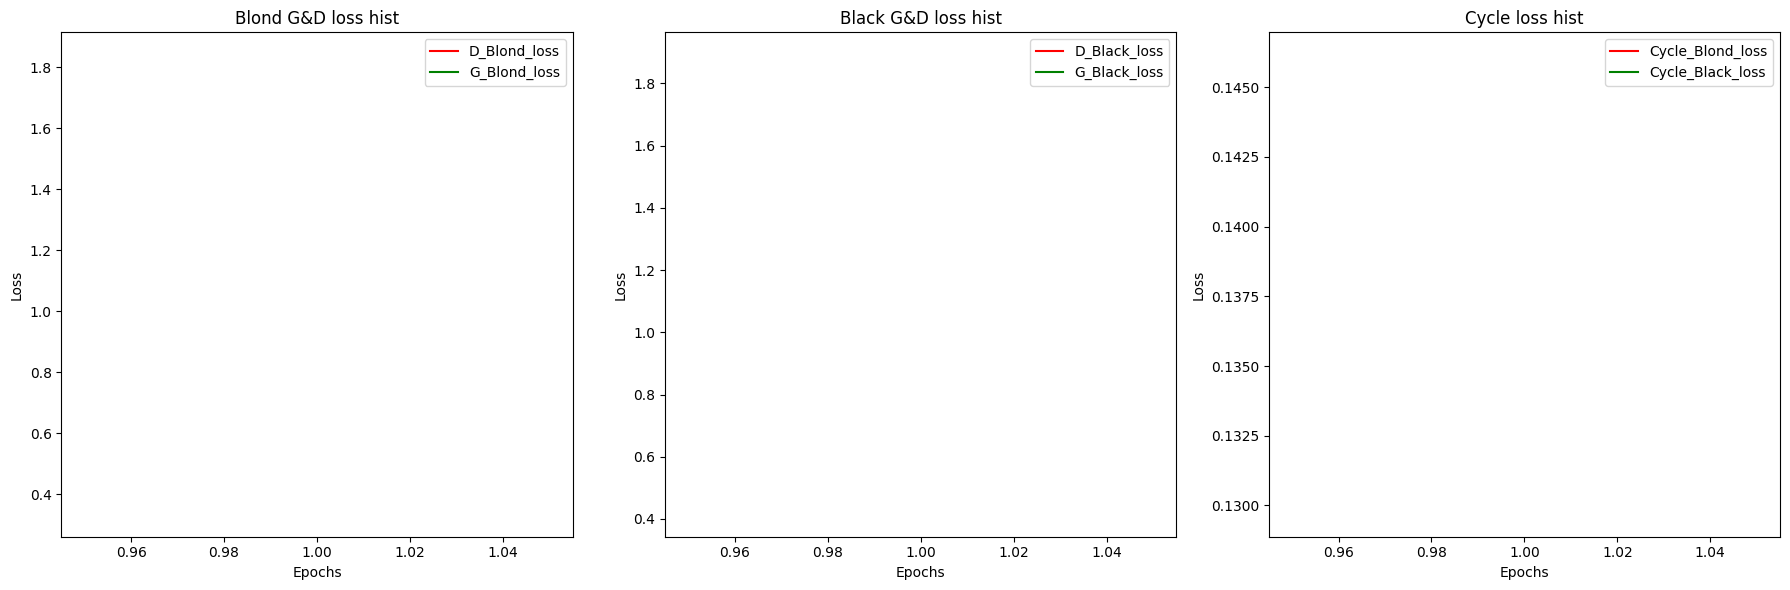

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 给每个子图分别生成 X 轴（因为 D 和 G 的 loss 数量可能不一致）
epochs_D_Blond = range(1, len(D_Blond_loss_hist) + 1)
epochs_G_Blond = range(1, len(G_Blond_loss_hist) + 1)

epochs_D_Black = range(1, len(D_Black_loss_hist) + 1)
epochs_G_Black = range(1, len(G_Black_loss_hist) + 1)

epochs_Cycle_Blond = range(1, len(Cycle_Blond_loss) + 1)
epochs_Cycle_Black = range(1, len(Cycle_Black_loss) + 1)

# 第一个子图
axes[0].plot(epochs_D_Blond, D_Blond_loss_hist, c='r', label='D_Blond_loss')
axes[0].plot(epochs_G_Blond, G_Blond_loss_hist, c='g', label='G_Blond_loss')
axes[0].set_title('Blond G&D loss hist')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()

# 第二个子图
axes[1].plot(epochs_D_Black, D_Black_loss_hist, c='r', label='D_Black_loss')
axes[1].plot(epochs_G_Black, G_Black_loss_hist, c='g', label='G_Black_loss')
axes[1].set_title('Black G&D loss hist')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()

# 第三个子图
axes[2].plot(epochs_Cycle_Blond, Cycle_Blond_loss, c='r', label='Cycle_Blond_loss')
axes[2].plot(epochs_Cycle_Black, Cycle_Black_loss, c='g', label='Cycle_Black_loss')
axes[2].set_title('Cycle loss hist')
axes[2].set_xlabel('Epochs')
axes[2].set_ylabel('Loss')
axes[2].legend()

fig.tight_layout()

# 先保存，再显示
fig.savefig('loss_history.png', dpi=300, bbox_inches='tight')
plt.show()